# Heart Disease Classification with Interpretable Machine Learning

**A BTech implementation inspired by Ozcan and Peker (2023)**  
Dataset: 918 records | Main method: CART | Extension: random forest  
Verified publication run: 15 November 2026

This notebook develops a complete experiment: source verification, data-quality audit,
training-only exploration, preprocessing, cross-validation, held-out evaluation, and
interpretation. The results are generated by the code, rather than copied from the paper.

**Research question:** Can an interpretable CART model classify heart disease in this
benchmark, and how does it compare with a majority baseline, logistic regression,
an unrestricted tree, and a random forest?

**Study scope:** This is retrospective disease-presence classification on a small
benchmark. It does not estimate future disease onset or establish clinical suitability.

The paper-inspired baseline is CART; the other classifiers are comparison models.

### Contents
1. Setup and source verification
2. Data quality and feature dictionary
3. Evaluation protocol and split
4. Training-only exploration
5. Preprocessing and model definitions
6. Training cross-validation and model selection
7. Final test evaluation and confidence intervals
8. Decision rules and feature importance
9. Subgroup observations, findings, and future work
10. Saved artifacts and references

## 1. Setup and source verification

Run the cells from top to bottom in the project environment. The notebook finds the
project root whether launched from the root folder or `notebooks/`. The reusable
helpers in `src/` are included with the project. Random seed **42** is fixed throughout.

In [1]:
from pathlib import Path
import sys, json, platform, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/project.py').exists() and (p / 'data/raw/heart.csv').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from src.project import (SEED, TARGET, FEATURES, NUMERIC, CATEGORICAL, load_dataset,
                         audit_data, InvalidMeasurementCleaner, evaluate_pipeline,
                         subgroup_metrics, extract_leaf_rules, write_json)
from src import charts

OUT = ROOT / 'output'
FIGURES, TABLES, MODELS = OUT/'figures', OUT/'tables', OUT/'models'
for folder in [FIGURES, TABLES, MODELS, ROOT/'data/processed']:
    folder.mkdir(parents=True, exist_ok=True)
charts.configure_style()
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
versions = {name: version(name) for name in
            ['numpy','pandas','scikit-learn','matplotlib','joblib','nbformat','nbclient','reportlab']}
print('Python:', platform.python_version())
display(pd.Series(versions, name='Installed version').to_frame())

Python: 3.12.14


,Installed version
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0
nbformat,5.11.1
nbclient,0.11.0
reportlab,4.4.9


In [2]:
df, provenance = load_dataset(ROOT)
print(f'Verified {len(df)} records, {len(FEATURES)} inputs, and one target.')
print('Source:', provenance['source_page'])
print('SHA-256:', provenance['csv_sha256'])
display(df.head(5))

Verified 918 records, 11 inputs, and one target.
Source: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
SHA-256: 948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


The source is [fedesoriano's Heart Failure Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).
Despite its title, the target `HeartDisease` is **presence (1) or absence (0) of heart disease**.
The 918-record combined dataset shares underlying source collections with the reviewed
paper. It is not a new independent cohort or an exact recreation of the paper's 745-record
cleaned sample. The original CSV is preserved unchanged in `data/raw/`.

## 2. Data quality and feature dictionary

We inspect source quality before modeling. This audit checks missing cells, duplicate
feature vectors, categories, class labels, and nonpositive blood pressure/cholesterol.
It does not use the final test labels to choose features or parameters.

**Cleaning rule:** treat nonpositive `RestingBP` and `Cholesterol` as missing measurements.
Retain zero values in binary variables and `Oldpeak`. Negative `Oldpeak` is also retained;
we do not remove observations simply because they are unusual.

,feature,dtype,empty_cells,unique_values,invalid_nonpositive
0,Age,int64,0,50,0
1,Sex,str,0,2,0
2,ChestPainType,str,0,4,0
3,RestingBP,int64,0,67,1
4,Cholesterol,int64,0,222,172
5,FastingBS,int64,0,2,0
6,RestingECG,str,0,3,0
7,MaxHR,int64,0,119,0
8,ExerciseAngina,str,0,2,0
9,Oldpeak,float64,0,53,0


Exact duplicate rows: 0
Repeated input vectors: 0
Nonpositive cholesterol: 172
Nonpositive resting BP: 1


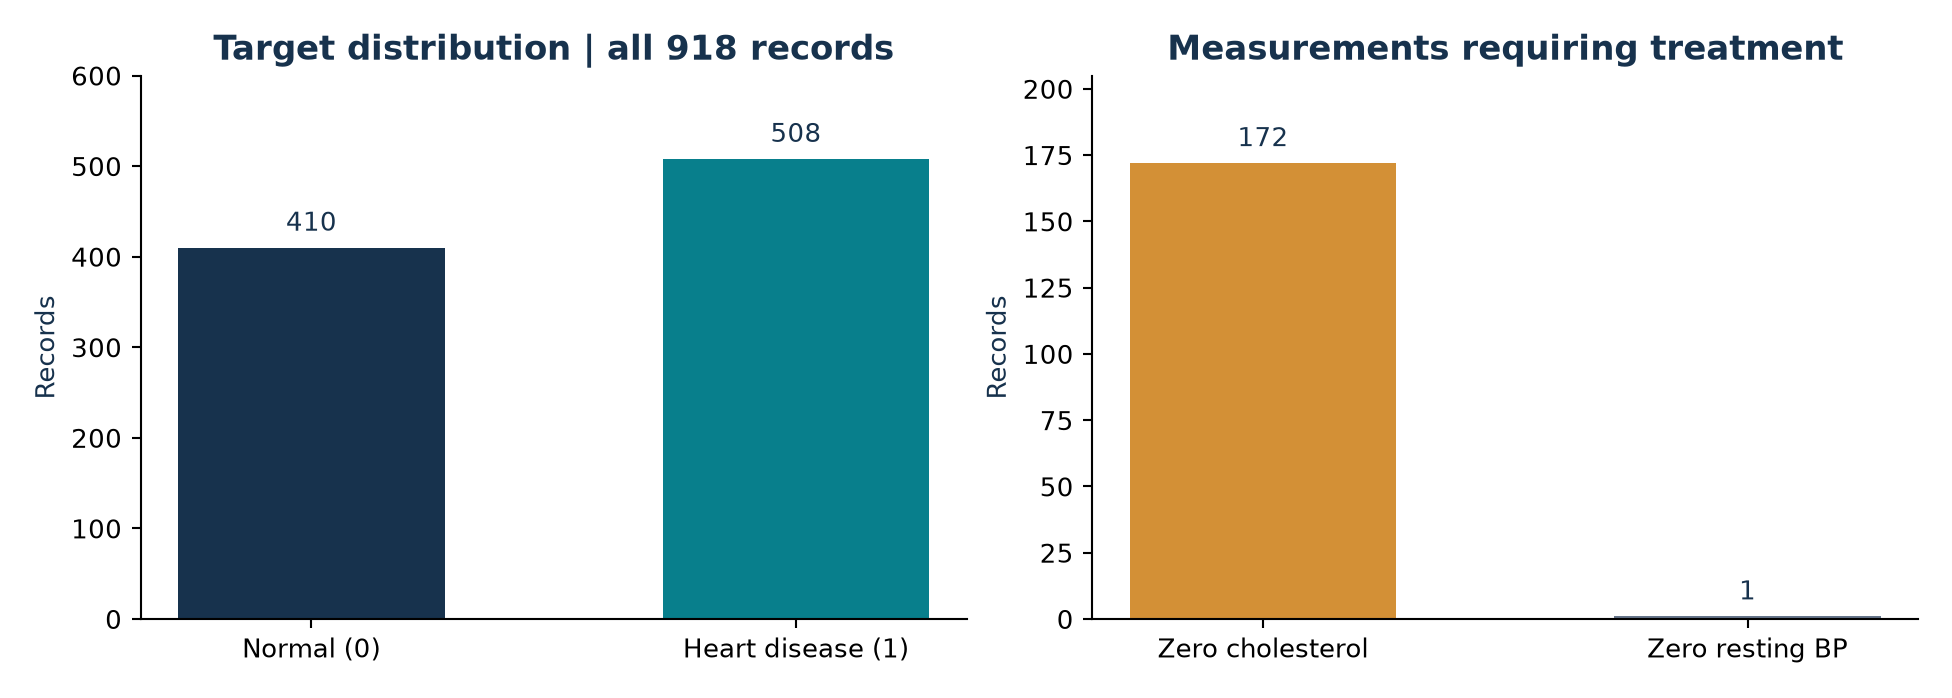

In [3]:
audit = audit_data(df)
audit.to_csv(TABLES/'data_quality.csv', index=False)
display(audit)
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated input vectors:', int(df[FEATURES].duplicated().sum()))
print('Nonpositive cholesterol:', int((df.Cholesterol <= 0).sum()))
print('Nonpositive resting BP:', int((df.RestingBP <= 0).sum()))
display(Image(filename=str(charts.dataset_audit(df, FIGURES)), width=1000))

In [4]:
dictionary = pd.DataFrame([
    ('Age', 'Numeric', 'Age in years'),
    ('Sex', 'Categorical', 'F or M, as recorded in the source'),
    ('ChestPainType', 'Categorical', 'TA=typical angina; ATA=atypical; NAP=non-anginal; ASY=asymptomatic'),
    ('RestingBP', 'Numeric', 'Resting blood pressure in mm Hg; zero treated as missing'),
    ('Cholesterol', 'Numeric', 'Serum cholesterol; zero treated as missing'),
    ('FastingBS', 'Binary', '1 if fasting blood sugar >120 mg/dL; otherwise 0'),
    ('RestingECG', 'Categorical', 'Normal, ST, or LVH'),
    ('MaxHR', 'Numeric', 'Maximum heart rate achieved, beats per minute'),
    ('ExerciseAngina', 'Categorical', 'Exercise-induced angina: Y or N'),
    ('Oldpeak', 'Numeric', 'Exercise-related ST depression; zero/negative values retained'),
    ('ST_Slope', 'Categorical', 'Up, Flat, or Down'),
    ('HeartDisease', 'Target', '1=heart disease; 0=normal'),
], columns=['Feature','Type','Meaning / handling'])
dictionary.to_csv(ROOT/'data/processed/feature_dictionary.csv',index=False)
display(dictionary)

,Feature,Type,Meaning / handling
0,Age,Numeric,Age in years
1,Sex,Categorical,"F or M, as recorded in the source"
2,ChestPainType,Categorical,TA=typical angina; ATA=atypical; NAP=non-angin...
3,RestingBP,Numeric,Resting blood pressure in mm Hg; zero treated ...
4,Cholesterol,Numeric,Serum cholesterol; zero treated as missing
5,FastingBS,Binary,1 if fasting blood sugar >120 mg/dL; otherwise 0
6,RestingECG,Categorical,"Normal, ST, or LVH"
7,MaxHR,Numeric,"Maximum heart rate achieved, beats per minute"
8,ExerciseAngina,Categorical,Exercise-induced angina: Y or N
9,Oldpeak,Numeric,Exercise-related ST depression; zero/negative ...


### Cleaning demonstration: preserve rows and valid zeros

This deterministic step changes only nonpositive cholesterol and blood pressure to
missing values. It learns no medians. All 918 rows remain available; actual imputation
is fitted later inside each training fold. RestingECG is a recorded summary category
(Normal, ST, LVH), rather than a raw ECG waveform.

In [5]:
cleaning_preview = InvalidMeasurementCleaner().fit_transform(df[FEATURES])
display(pd.DataFrame({
    'Missing before': df[FEATURES].isna().sum(),
    'Missing after deterministic cleaning': cleaning_preview.isna().sum(),
}))
assert len(cleaning_preview) == len(df)
assert cleaning_preview['Oldpeak'].equals(df['Oldpeak'])
assert cleaning_preview['FastingBS'].equals(df['FastingBS'])
print('Rows retained:', len(cleaning_preview), '| Medians have not been fitted.')

,Missing before,Missing after deterministic cleaning
Age,0,0
Sex,0,0
ChestPainType,0,0
RestingBP,0,1
Cholesterol,0,172
FastingBS,0,0
RestingECG,0,0
MaxHR,0,0
ExerciseAngina,0,0
Oldpeak,0,0


Rows retained: 918 | Medians have not been fitted.


## 3. Evaluation protocol and split

The following decisions are fixed before viewing test performance:

- Reserve **20%** of records as a stratified test set; use the remaining **80%** for training.
- Use the same shuffled **five-fold stratified cross-validation** for every candidate.
- Select hyperparameters and the overall candidate using **mean training-CV F1**.
  F1 balances precision and recall, but it is not a clinical cost function.
- Imputation, missingness indicators, encoding, and scaling stay **inside each pipeline**.
- Use each fitted estimator's default `predict` behavior; no threshold is chosen from the test set.
- Evaluate all predefined models on the reserved test set for comparison. The CV-selected
  candidate remains the selected candidate regardless of test ranking.

CV scores after hyperparameter search can be optimistic; the final holdout is the main
performance check. The split membership and CV validation-fold membership are exported.

In [6]:
X, y = df[FEATURES].copy(), df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)

membership = pd.DataFrame({'source_row':df.index, 'split':'test', 'cv_validation_fold':-1})
membership.loc[X_train.index,'split'] = 'train'
for fold, (_, valid_position) in enumerate(cv.split(X_train, y_train)):
    membership.loc[X_train.index[valid_position],'cv_validation_fold'] = fold
membership.to_csv(ROOT/'data/processed/split_assignments.csv',index=False)
split_table = pd.DataFrame({
    'Split':['Train','Test'], 'Records':[len(X_train),len(X_test)],
    'Normal':[int((y_train==0).sum()),int((y_test==0).sum())],
    'Heart disease':[int((y_train==1).sum()),int((y_test==1).sum())]})
display(split_table)

,Split,Records,Normal,Heart disease
0,Train,734,328,406
1,Test,184,82,102


## 4. Training-only exploration

The plots below use training records only. Associations in this selected benchmark
cannot establish causation or population-level disease risk. ST slope is a recorded
exercise-test feature, so this is not a diagnosis model using only basic lifestyle data.

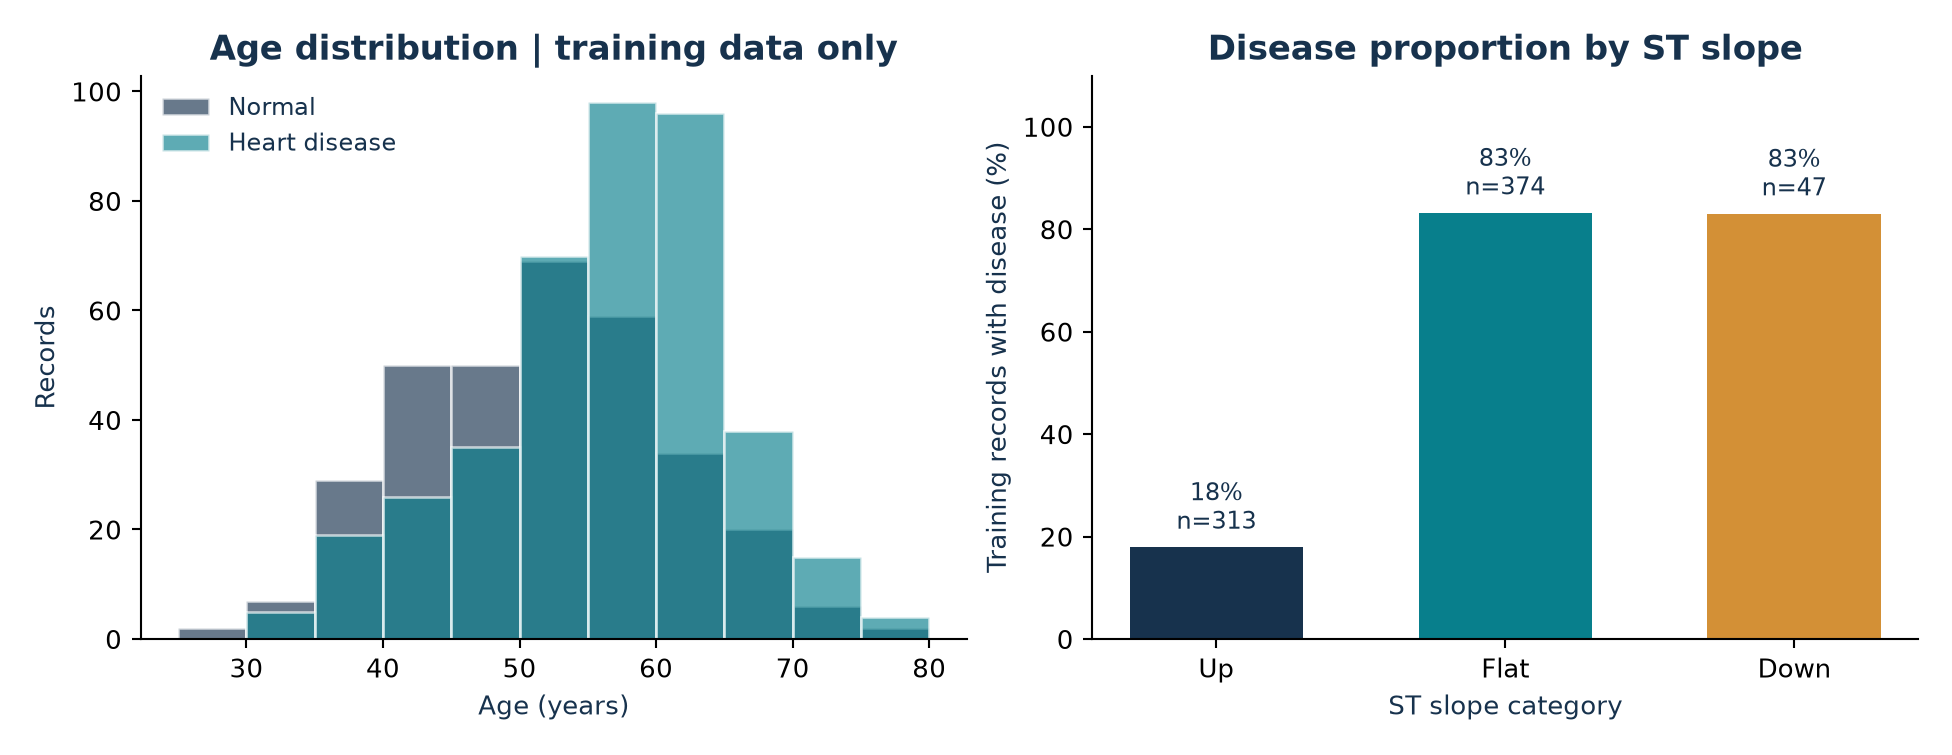

,count,mean,std,min,25%,50%,75%,max
Age,734.0,53.85,9.44,29.0,47.0,55.0,61.00,77.0
RestingBP,734.0,132.87,18.08,92.0,120.0,130.0,141.00,200.0
Cholesterol,734.0,203.23,108.40,0.0,180.0,225.0,269.75,603.0
FastingBS,734.0,0.23,0.42,0.0,0.0,0.0,0.00,1.0
MaxHR,734.0,136.38,25.83,60.0,119.0,138.0,156.00,202.0
Oldpeak,734.0,0.87,1.06,-2.6,0.0,0.5,1.50,5.6


In [7]:
display(Image(filename=str(charts.training_eda(X_train,y_train,FIGURES)),width=1000))
display(X_train[NUMERIC].describe().T.round(2))

## 5. Preprocessing and model definitions

For numerical inputs, a median imputer is fitted on the current training fold.
Missingness indicators retain whether a measurement was unavailable. Nominal categories
are one-hot encoded, avoiding a false numeric order. Unknown categories are handled
without refitting the encoder. Logistic regression also receives standardized numerical
inputs; the tree models do not require scaling.

The unrestricted tree shows the behavior of a flexible CART model. The tuned CART limits
depth, minimum leaf size, pruning strength (`ccp_alpha`), and optionally balances class
weights. The random forest is an implemented extension that averages multiple trees.
All models use a single CPU worker for predictable resource use.

### Complete preprocessing pipeline

The function below is the same implementation supplied in `src/project.py`. The
cleaner is imported from that module so saved models can be loaded in a fresh session.
Each CV fit receives its own imputer, encoder, and (for LR) scaler.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [9]:
def make_model_pipeline(estimator, *, scale_numeric=False, features=None) -> Pipeline:
    features = FEATURES if features is None else features
    numeric = [x for x in NUMERIC if x in features]
    categorical = [x for x in CATEGORICAL if x in features]
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    preprocess = ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric),
            (
                "categorical",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline(
        [
            ("clean", InvalidMeasurementCleaner()),
            ("preprocess", preprocess),
            ("model", estimator),
        ]
    )

In [10]:
specifications = {
    'Majority baseline': (make_model_pipeline(DummyClassifier(strategy='most_frequent')), {}),
    'Logistic regression': (
        make_model_pipeline(LogisticRegression(max_iter=2000,random_state=SEED),scale_numeric=True),
        {'model__C':[0.1,1.0,10.0], 'model__class_weight':[None,'balanced']}),
    'Unrestricted CART': (
        make_model_pipeline(DecisionTreeClassifier(random_state=SEED)), {}),
    'Tuned CART': (
        make_model_pipeline(DecisionTreeClassifier(criterion='gini',random_state=SEED)),
        {'model__max_depth':[2,3,4,5,6], 'model__min_samples_leaf':[5,10,20],
         'model__ccp_alpha':[0.0,0.005,0.01], 'model__class_weight':[None,'balanced']}),
    'Random forest': (
        make_model_pipeline(RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1)),
        {'model__max_depth':[None,8], 'model__min_samples_leaf':[2,5],
         'model__max_features':['sqrt',0.75]}),
}
scoring = {'f1':'f1','recall':'recall','roc_auc':'roc_auc'}
print('Defined five comparison models before test evaluation.')

Defined five comparison models before test evaluation.


## 6. Training cross-validation and model selection

Each search fits only `X_train` and `y_train`. The saved CV result files include all
candidate settings and their scores, including unsuccessful settings with lower scores.
No search is rerun to chase a better test result.

Majority baseline: CV F1=0.7123; 0.2s


Logistic regression: CV F1=0.8761; 1.2s
Unrestricted CART: CV F1=0.8170; 0.2s


Tuned CART: CV F1=0.8646; 13.8s


Random forest: CV F1=0.8757; 9.7s


,model,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_roc_auc_mean,candidate_settings
0,Logistic regression,0.8761,0.0277,0.8917,0.9268,6
1,Random forest,0.8757,0.0262,0.8990,0.9315,8
2,Tuned CART,0.8646,0.0313,0.8869,0.9044,90
3,Unrestricted CART,0.8170,0.0522,0.8079,0.8002,1
4,Majority baseline,0.7123,0.0023,1.0000,0.5000,1


**Selected before test evaluation: Logistic regression.** CART remains the main interpretability model.

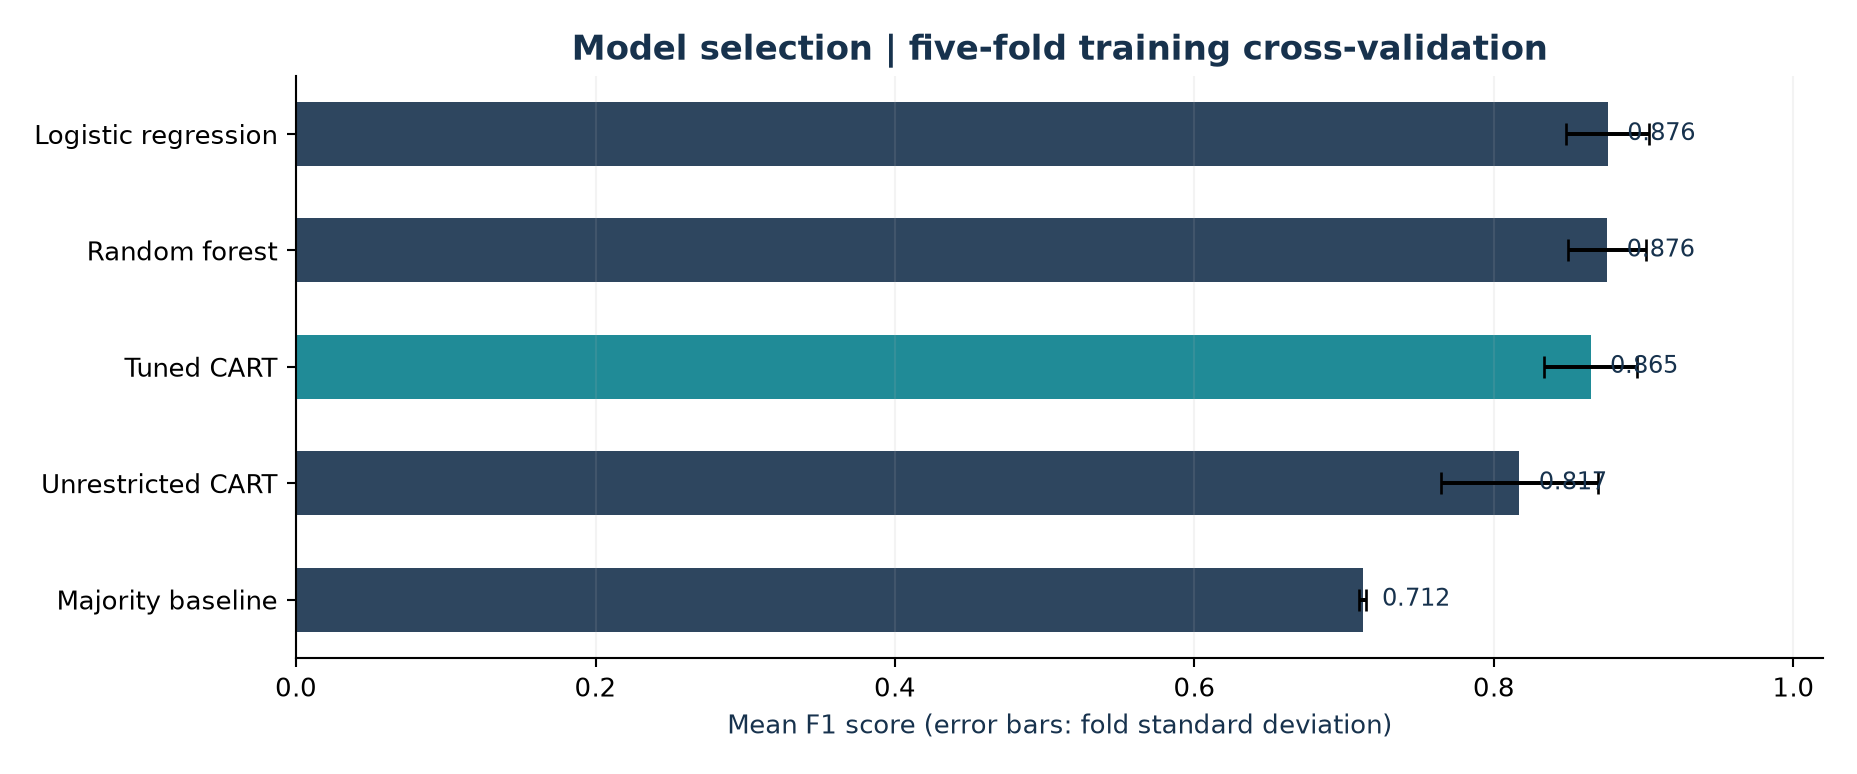

In [11]:
searches, fitted_models, cv_rows = {}, {}, []
for name, (pipeline, grid) in specifications.items():
    started = time.perf_counter()
    search = GridSearchCV(pipeline, grid, scoring=scoring, refit='f1', cv=cv,
                          return_train_score=True, n_jobs=1, error_score='raise')
    search.fit(X_train,y_train)
    searches[name], fitted_models[name] = search, search.best_estimator_
    index = search.best_index_
    cv_rows.append({
        'model':name, 'cv_f1_mean':float(search.best_score_),
        'cv_f1_std':float(search.cv_results_['std_test_f1'][index]),
        'cv_recall_mean':float(search.cv_results_['mean_test_recall'][index]),
        'cv_roc_auc_mean':float(search.cv_results_['mean_test_roc_auc'][index]),
        'candidate_settings':len(search.cv_results_['params']),
        'best_parameters':json.dumps(search.best_params_,sort_keys=True)})
    slug = name.lower().replace(' ','_')
    pd.DataFrame(search.cv_results_).to_csv(TABLES/f'cv_search_{slug}.csv',index=False)
    print(f'{name}: CV F1={search.best_score_:.4f}; {time.perf_counter()-started:.1f}s')

cv_results = pd.DataFrame(cv_rows).sort_values('cv_f1_mean',ascending=False).reset_index(drop=True)
selected_name = cv_results.loc[cv_results.model.ne('Majority baseline')].iloc[0]['model']
cv_results.to_csv(TABLES/'cross_validation_summary.csv',index=False)
display(cv_results.drop(columns='best_parameters').round(4))
display(Markdown(f'**Selected before test evaluation: {selected_name}.** CART remains the main interpretability model.'))
display(Image(filename=str(charts.cv_comparison(cv_results,FIGURES)),width=950))

### Inspect training-only imputation

These are the numerical medians learned by the fitted CART pipeline. They must agree
with the cleaned training records. Neither test values nor test labels enter this fit.

In [12]:
fitted_cart = fitted_models['Tuned CART']
clean_train = fitted_cart.named_steps['clean'].transform(X_train)
imputer = fitted_cart.named_steps['preprocess'].named_transformers_['numeric'].named_steps['impute']
display(pd.DataFrame({
    'Cleaned training median': clean_train[NUMERIC].median(),
    'Fitted imputer median': imputer.statistics_,
}))
assert np.allclose(imputer.statistics_, clean_train[NUMERIC].median())

,Cleaned training median,Fitted imputer median
Age,55.0,55.0
RestingBP,130.0,130.0
Cholesterol,238.0,238.0
FastingBS,0.0,0.0
MaxHR,138.0,138.0
Oldpeak,0.5,0.5


## 7. Final test evaluation and confidence intervals

**Positive class:** heart disease (`1`). Confusion matrices use **actual labels as rows**
and **predicted labels as columns**, ordered `[0,1]`. Recall is `TP/(TP+FN)`, precision is
`TP/(TP+FP)`, and specificity is `TN/(TN+FP)`. This explicit orientation avoids the metric
label inconsistency identified in the paper review.

Accuracy, precision, recall, specificity, F1, ROC AUC, average precision, and Brier score
are saved. Lower Brier score is better. Accuracy and recall receive 95% Wilson intervals;
these describe sampling uncertainty conditional on this test set and do not capture
dataset shift or the full model-selection process.

In [13]:
metric_rows, prediction_rows = [], []
test_predictions, test_probabilities = {}, {}
for name in cv_results.model:  # Preserve the training-CV order, not test ranking.
    pipeline = fitted_models[name]
    metrics, predicted, probability = evaluate_pipeline(pipeline,X_test,y_test)
    training_metrics, _, _ = evaluate_pipeline(pipeline,X_train,y_train)
    metrics.update({'model':name, 'train_accuracy':training_metrics['accuracy'],
                    'train_f1':training_metrics['f1']})
    metric_rows.append(metrics)
    test_predictions[name],test_probabilities[name] = predicted,probability
    prediction_rows.extend({'model':name,'source_row':int(row),'actual':int(actual),
                            'predicted':int(pred),'probability':float(prob)}
                           for row,actual,pred,prob in zip(X_test.index,y_test,predicted,probability))
metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(TABLES/'model_metrics.csv',index=False)
pd.DataFrame(prediction_rows).to_csv(TABLES/'test_predictions.csv',index=False)
columns = ['model','train_accuracy','accuracy','precision','recall','specificity','f1','roc_auc']
display(metrics_df[columns].round(4).set_index('model'))

cart_result = metrics_df.set_index('model').loc['Tuned CART']
chosen_result = metrics_df.set_index('model').loc[selected_name]
display(Markdown(
    f"**Tuned CART:** test accuracy {cart_result.accuracy:.1%}, "
    f"F1 {cart_result.f1:.3f}, recall {cart_result.recall:.1%}. "
    f"Its 95% accuracy interval is {cart_result.accuracy_ci_low:.1%} to {cart_result.accuracy_ci_high:.1%}. "
    f"It misses {int(cart_result.fn)} of {int(cart_result.tp+cart_result.fn)} disease cases. "
    f"The CV-selected {selected_name} has test F1 {chosen_result.f1:.3f}."))

,train_accuracy,accuracy,precision,recall,specificity,f1,roc_auc
model,,,,,,,
Logistic regression,0.8651,0.9022,0.8962,0.9314,0.8659,0.9135,0.9346
Random forest,0.9401,0.9076,0.8972,0.9412,0.8659,0.9187,0.9362
Tuned CART,0.8624,0.7935,0.8200,0.8039,0.7805,0.8119,0.8613
Unrestricted CART,1.0000,0.7337,0.7789,0.7255,0.7439,0.7513,0.7347
Majority baseline,0.5531,0.5543,0.5543,1.0000,0.0000,0.7133,0.5000


**Tuned CART:** test accuracy 79.3%, F1 0.812, recall 80.4%. Its 95% accuracy interval is 72.9% to 84.6%. It misses 20 of 102 disease cases. The CV-selected Logistic regression has test F1 0.913.

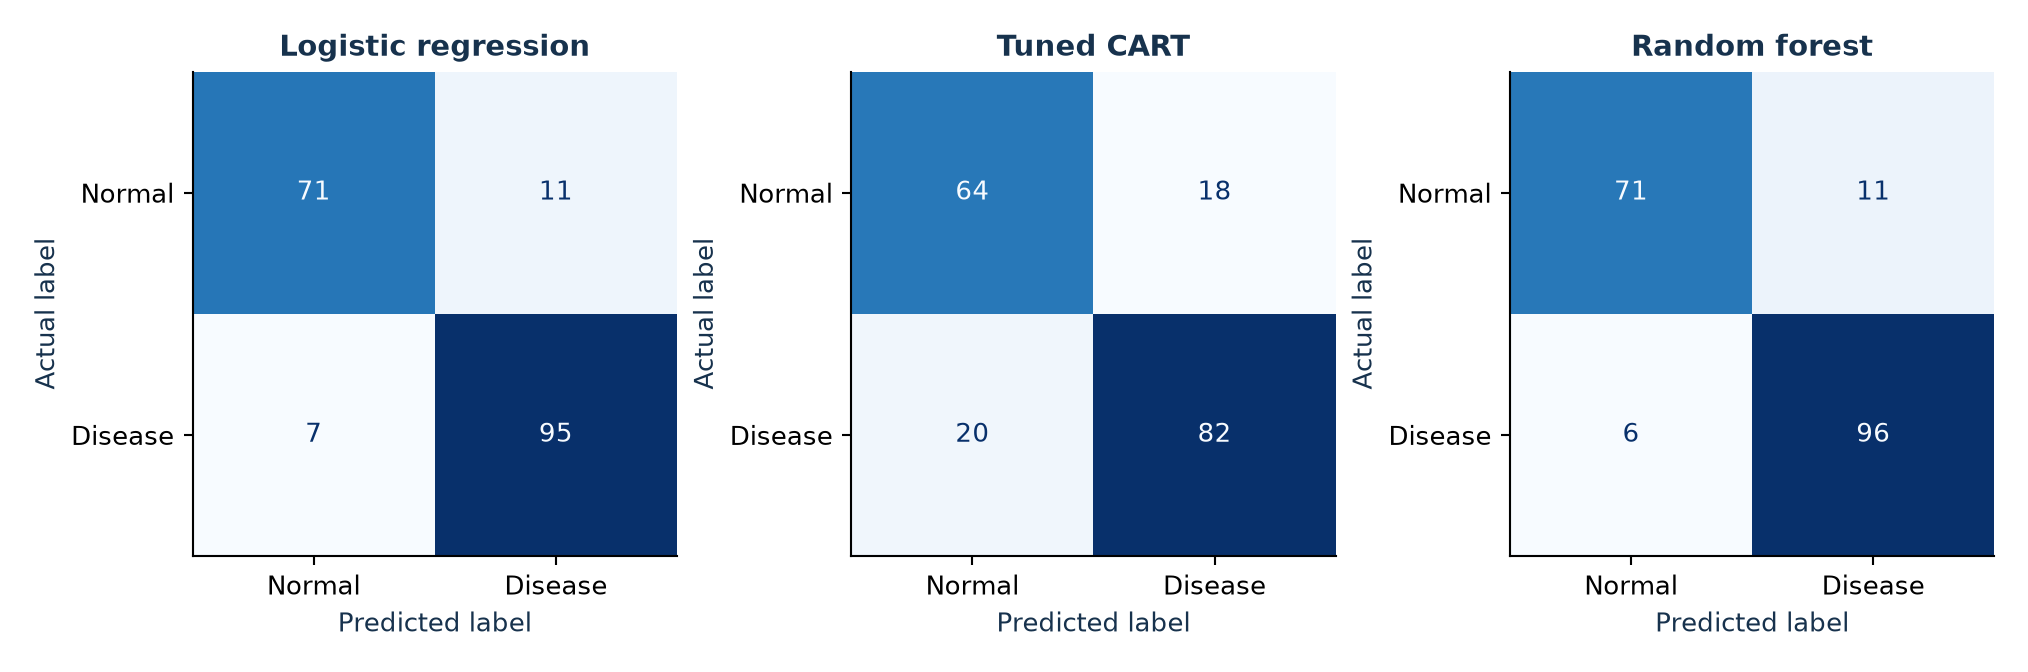

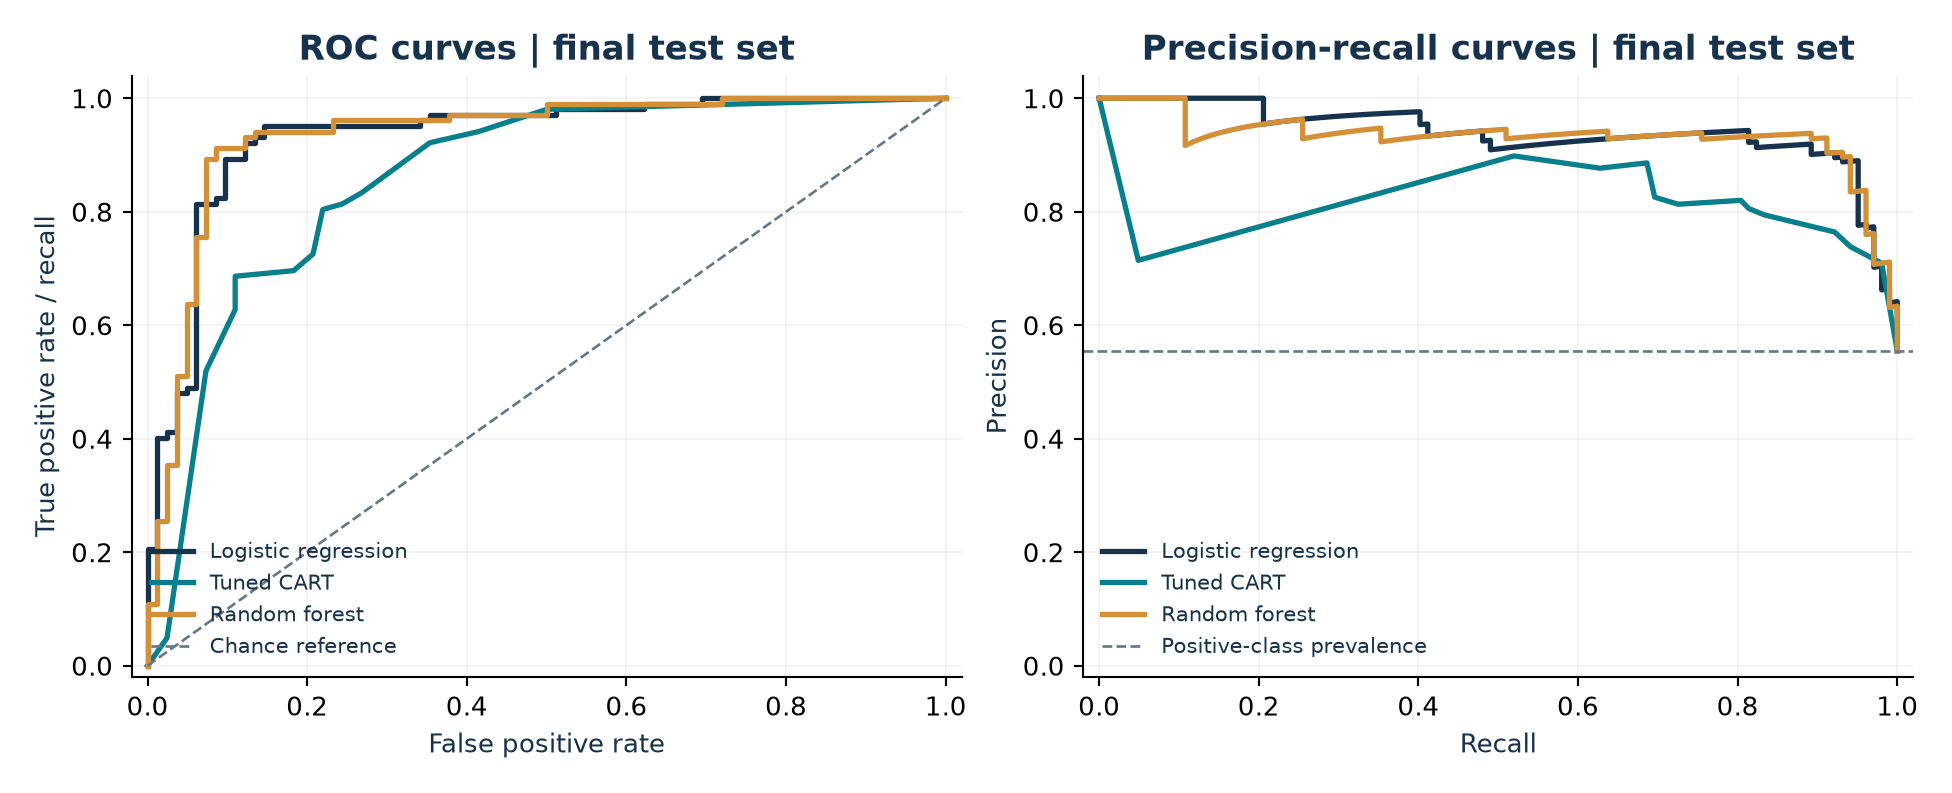

In [14]:
display(Image(filename=str(charts.confusion_panels(y_test,test_predictions,FIGURES)),width=1050))
display(Image(filename=str(charts.discrimination_curves(y_test,test_probabilities,FIGURES)),width=1000))

The models have now been evaluated on the test set. Differences on this one split are
descriptive comparisons, not proof of statistical superiority. We retain the previously
selected model and do not adjust its parameters or decision threshold from these results.

## 8. Decision rules and feature importance

We inspect the fitted CART after final evaluation. The tree preview shows only the first
three split levels; the full rule set is exported. `value` in the tree diagram is class
composition and can be weighted if class weights are selected.

Permutation importance measures how much test F1 falls when one original input is
shuffled, using 20 fixed-seed repeats. It is explanatory analysis of a frozen model,
not a basis for further tuning. Error bars show variability across shuffles, not a
confidence interval for the population. Correlated inputs can share importance.

,Selected CART setting
model__ccp_alpha,0.0
model__class_weight,NaN
model__max_depth,4.0
model__min_samples_leaf,10.0


Tree depth: 4
Leaf nodes: 15


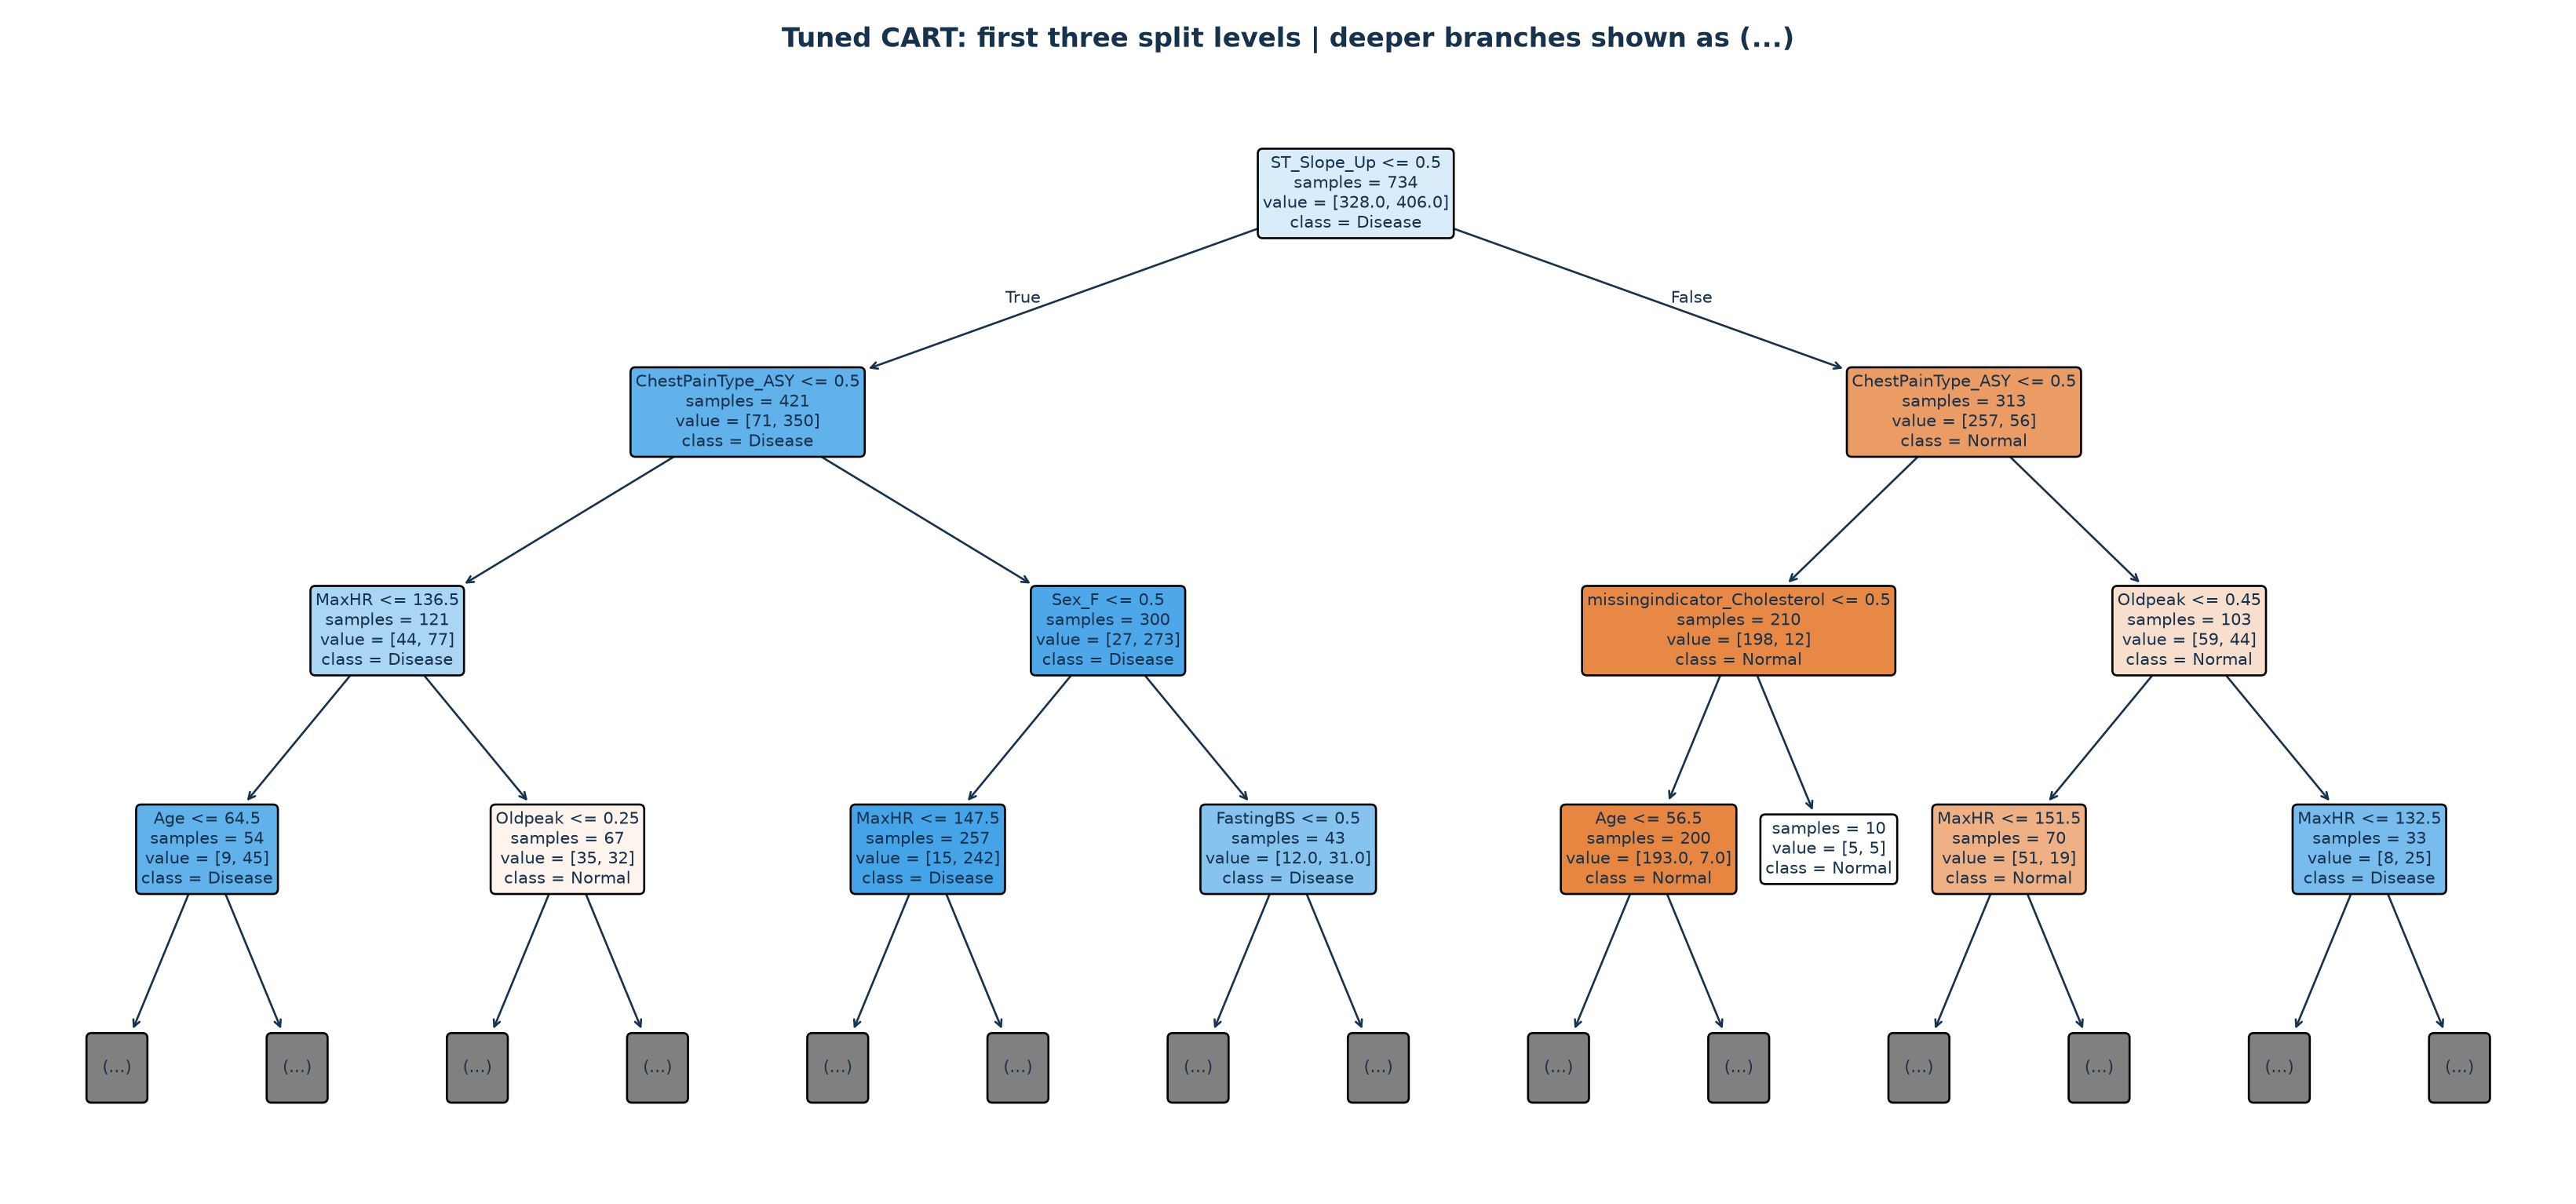

,leaf,rule,training_records,predicted_class,fitted_disease_fraction
0,11,ST_Slope is not Up AND ChestPainType is ASY AN...,222,1,0.9595
1,19,ST_Slope is Up AND ChestPainType is not ASY AN...,157,0,0.0064
2,8,ST_Slope is not Up AND ChestPainType is not AS...,53,0,0.4151
3,20,ST_Slope is Up AND ChestPainType is not ASY AN...,43,0,0.1395


Complete rules: output/tables/cart_rules.txt


In [15]:
cart = fitted_models['Tuned CART']
display(pd.Series(searches['Tuned CART'].best_params_,name='Selected CART setting').to_frame())
print('Tree depth:',cart.named_steps['model'].get_depth())
print('Leaf nodes:',cart.named_steps['model'].get_n_leaves())
display(Image(filename=str(charts.decision_tree_view(cart,FIGURES)),width=1100))

leaf_rules = extract_leaf_rules(cart)
leaf_rules.to_csv(TABLES/'cart_leaf_rules.csv',index=False)
full_rules = export_text(cart.named_steps['model'],
                         feature_names=list(cart.named_steps['preprocess'].get_feature_names_out()),
                         max_depth=20,decimals=2)
(TABLES/'cart_rules.txt').write_text(full_rules,encoding='utf-8')
display(leaf_rules.head(4))
print('Complete rules: output/tables/cart_rules.txt')

,feature,f1_decrease_mean,f1_decrease_std
0,ST_Slope,0.1224,0.0219
1,ChestPainType,0.0510,0.0187
2,MaxHR,0.0188,0.0152
3,Oldpeak,0.0045,0.0191
4,Age,0.0000,0.0000
5,Sex,0.0000,0.0000
6,RestingBP,0.0000,0.0000
7,RestingECG,0.0000,0.0000
8,FastingBS,0.0000,0.0000
9,Cholesterol,0.0000,0.0000


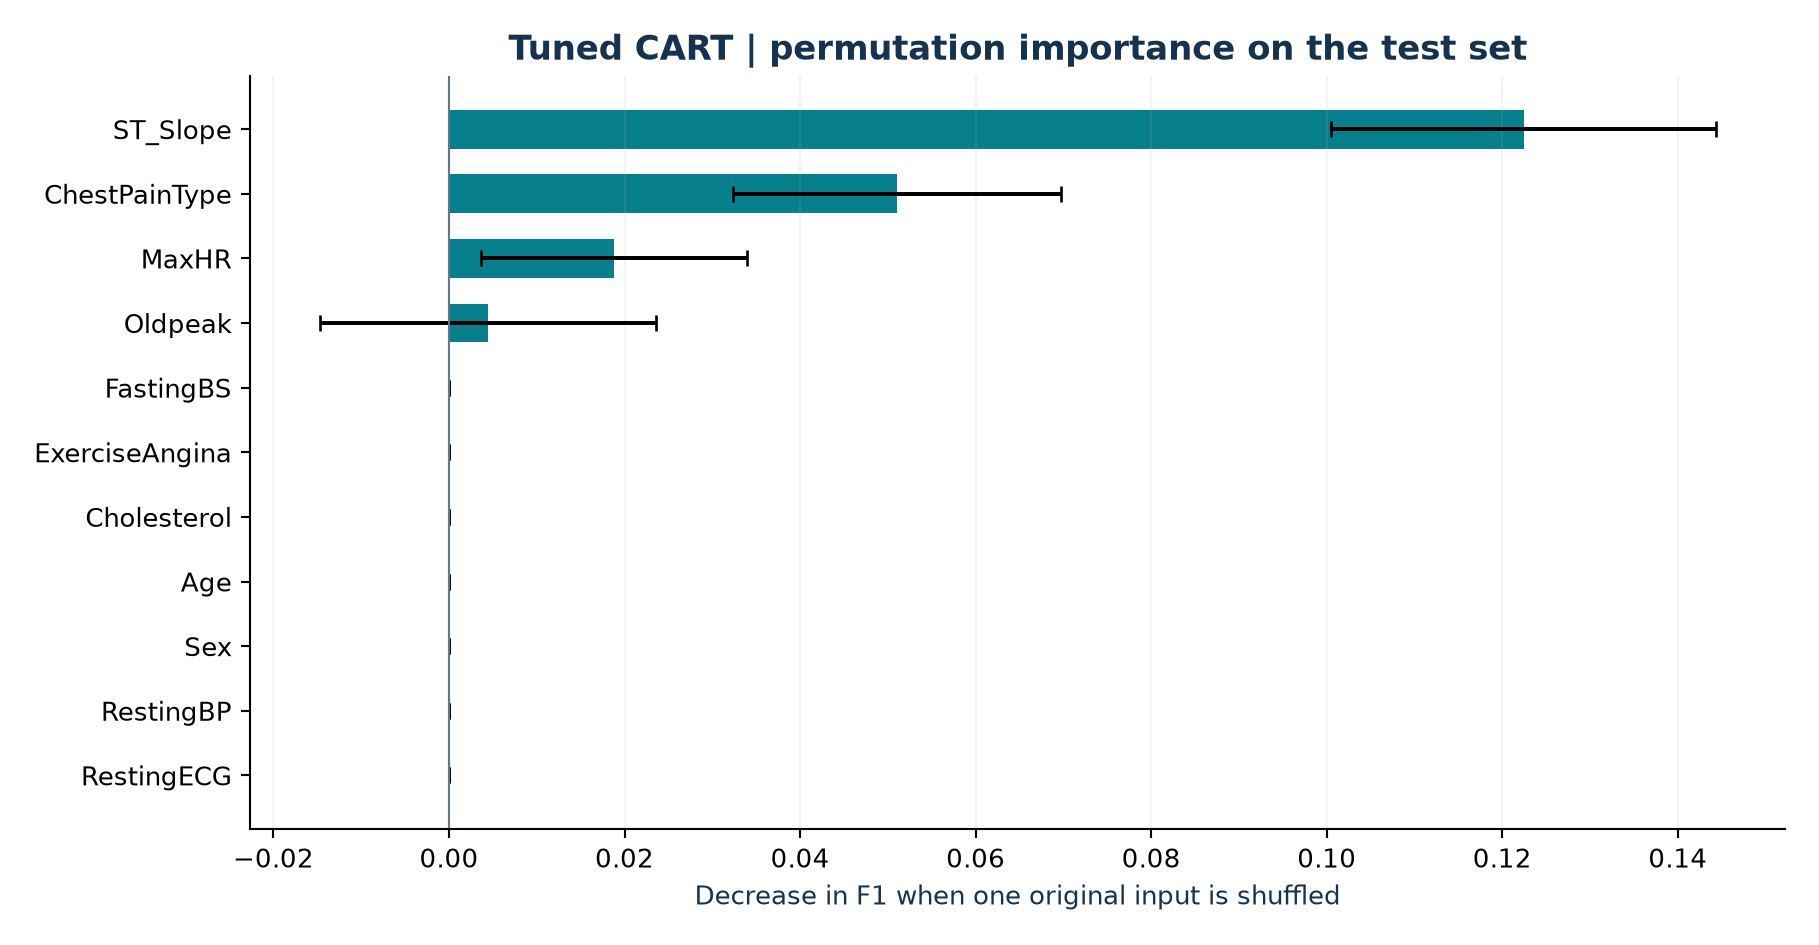

In [16]:
permuted = permutation_importance(cart,X_test,y_test,n_repeats=20,
                                 random_state=SEED,scoring='f1',n_jobs=1)
importance = pd.DataFrame({'feature':FEATURES,'f1_decrease_mean':permuted.importances_mean,
                           'f1_decrease_std':permuted.importances_std})
importance = importance.sort_values('f1_decrease_mean',ascending=False).reset_index(drop=True)
importance.to_csv(TABLES/'cart_permutation_importance.csv',index=False)
display(importance.round(4))
display(Image(filename=str(charts.feature_importance(importance,FIGURES)),width=950))

A rule's fitted disease fraction is the tree's training composition (weighted when
class weights apply). It is not a calibrated medical risk estimate. One-hot rules such
as `ST_Slope_Up > 0.5` mean that the category is `Up`; the CSV rule table translates these
conditions into readable wording. Numeric conditions apply after training-data imputation.

## 9. Subgroup observations, findings, and future work

The following audit uses the **CV-selected model** and fixed groups: recorded sex and
age below 55 versus 55 or above. Small positive-case denominators can produce unstable
recall. These summaries do not establish fairness or support different treatment rules.

In [17]:
subgroups = subgroup_metrics(y_test,test_predictions[selected_name],X_test)
subgroups.to_csv(TABLES/'selected_model_subgroups.csv',index=False)
display(subgroups.round(4))

,group,n,positive_cases,accuracy,recall,recall_ci_low,recall_ci_high,specificity,false_negatives
0,Sex: female,38,6,0.9211,0.8333,0.4365,0.9699,0.9375,1
1,Sex: male,146,96,0.8973,0.9375,0.8703,0.9710,0.8200,6
2,Age: below 55,109,42,0.8899,0.8810,0.7500,0.9481,0.8955,5
3,Age: 55 or above,75,60,0.9200,0.9667,0.8864,0.9908,0.7333,2


In [18]:
unrestricted = metrics_df.set_index('model').loc['Unrestricted CART']
forest = metrics_df.set_index('model').loc['Random forest']
top_features = ', '.join(importance.head(3).feature)
display(Markdown(f'''
### What this implementation found

- Retaining records through fold-specific imputation allowed all **{len(df)} records** to remain in the experiment.
- The unrestricted tree's training accuracy was **{unrestricted.train_accuracy:.1%}**, versus **{unrestricted.accuracy:.1%}** on the test set. This gap illustrates why training accuracy alone is insufficient.
- Tuned CART reached **{cart_result.accuracy:.1%} accuracy** and **{cart_result.f1:.3f} F1**. Its test confusion matrix contains **{int(cart_result.fn)} false negatives** and **{int(cart_result.fp)} false positives**.
- The random forest extension reached **{forest.accuracy:.1%} accuracy** and **{forest.f1:.3f} F1**; its F1 difference from CART was **{forest.f1-cart_result.f1:+.3f}** on this split.
- The largest CART permutation effects were for **{top_features}**. These are model associations, not causes.
- The overall model selected by training CV was **{selected_name}**. Test-set ranking was not used to change that choice.

### Experimental safeguards

We implemented verified source preservation, fold-specific preprocessing, a fixed stratified
holdout, explicit metric formulas, a full parameter-search record, two additional model
families, confidence intervals, a subgroup audit, and reproducible artifact exports.
These improve the experimental workflow; they do not guarantee a better clinical model.
'''))


### What this implementation found

- Retaining records through fold-specific imputation allowed all **918 records** to remain in the experiment.
- The unrestricted tree's training accuracy was **100.0%**, versus **73.4%** on the test set. This gap illustrates why training accuracy alone is insufficient.
- Tuned CART reached **79.3% accuracy** and **0.812 F1**. Its test confusion matrix contains **20 false negatives** and **18 false positives**.
- The random forest extension reached **90.8% accuracy** and **0.919 F1**; its F1 difference from CART was **+0.107** on this split.
- The largest CART permutation effects were for **ST_Slope, ChestPainType, MaxHR**. These are model associations, not causes.
- The overall model selected by training CV was **Logistic regression**. Test-set ranking was not used to change that choice.

### Experimental safeguards

We implemented verified source preservation, fold-specific preprocessing, a fixed stratified
holdout, explicit metric formulas, a full parameter-search record, two additional model
families, confidence intervals, a subgroup audit, and reproducible artifact exports.
These improve the experimental workflow; they do not guarantee a better clinical model.


### Limitations and additions worth investigating

1. **External validation:** obtain an independent cohort with compatible features and labels.
   Cleveland and Statlog are source components of this combined benchmark and must not
   be presented as independent external tests.
2. **Missingness and source effects:** zero cholesterol may reflect collection practices.
   Missingness indicators could learn site-related patterns. Compare alternative imputation
   policies and validation by source if trustworthy source identifiers become available.
3. **Robustness:** use nested or repeated cross-validation, with preprocessing inside every
   fold, and report variability instead of relying on one holdout split.
4. **Decision thresholds and calibration:** use a separate validation procedure to study
   recall/precision trade-offs and calibrated probabilities. Do not select thresholds from
   the final test set. Default class predictions are used in this implementation.
5. **Richer features:** investigate smoking, family history, and other relevant variables only
   when a suitable dataset supports them. Do not invent missing clinical information.
6. **Student-facing addition:** a small Streamlit demonstration could display a saved model's
   prediction and rule path using sample records, with clear limits on interpretation.

The paper reported approximately 87% accuracy, but our dataset cleaning, language,
categorical handling, tuning, and test split differ. A numerical comparison cannot establish
that our implementation outperforms the paper. Single-tree fractions and random-forest
probabilities are not validated clinical risk estimates.

## 10. Save the verified experiment artifacts

The saved model files contain the entire fitted preprocessing pipeline. Only load model
files from trusted sources. The raw CSV, split assignments, CV logs, test predictions,
metrics, figures, rules, and summary JSON together make the experiment inspectable.

In [19]:
joblib.dump(cart,MODELS/'tuned_cart.joblib')
joblib.dump(fitted_models[selected_name],MODELS/'selected_model.joblib')
summary = {
    'project':'BTech Heart Disease Classification', 'client_date':'2026-11-15', 'seed':SEED,
    'python_version':platform.python_version(), 'versions':versions,
    'dataset':{'rows':len(df),'features':len(FEATURES),'normal':int((y==0).sum()),
               'disease':int((y==1).sum()),'source_sha256':provenance['csv_sha256'],
               'zero_cholesterol':int((df.Cholesterol<=0).sum()),
               'zero_resting_bp':int((df.RestingBP<=0).sum())},
    'split':{'train':len(X_train),'test':len(X_test),
             'train_positive':int(y_train.sum()),'test_positive':int(y_test.sum()),
             'folds':5,'stratified':True},
    'selection':{'metric':'mean training-CV F1','selected_before_test':selected_name,
                 'no_test_based_retuning':True},
    'cv_summary':cv_results.to_dict(orient='records'),
    'test_results':metrics_df.to_dict(orient='records'),
    'cart':{'parameters':searches['Tuned CART'].best_params_,
            'depth':int(cart.named_steps['model'].get_depth()),
            'leaves':int(cart.named_steps['model'].get_n_leaves())},
    'top_cart_permutation_features':importance.head(3).feature.tolist(),
    'completed':True,
}
write_json(OUT/'results.json',summary)
print('Experiment complete. All reported results have been saved.')
print('Next: generate the PDF with python scripts/build_baseline_report.py')

Experiment complete. All reported results have been saved.
Next: generate the PDF with python scripts/build_baseline_report.py


## References

1. Ozcan, M., & Peker, S. (2023). *A classification and regression tree algorithm for heart disease modeling and prediction*. Healthcare Analytics, 3, 100130. [DOI](https://doi.org/10.1016/j.health.2022.100130).
2. fedesoriano. *Heart Failure Prediction Dataset*. [Kaggle source](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). Source metadata and SHA-256 are recorded in `data/raw/provenance.json`.
3. UCI Machine Learning Repository. [Heart Disease](https://archive.ics.uci.edu/dataset/45/heart%2Bdisease). Background on the original source collections and target coding.
4. scikit-learn. [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

AI assisted the preparation of the code and explanations. Numerical findings come from
executing this notebook on the downloaded dataset. The interpretation should be reviewed
and understood by the student team before presenting the project.